# NIDSZ — Network Intrusion Detection & Zero-Day Generalization (UNSW-NB15)

Étude de cybersécurité prédictive sur les **257 673 flux réseau officiels UNSW-NB15** (`175 341` entraînement / `82 332` holdout officiel, zéro mélange). Ce notebook reproduit l'audit de schéma, l'ablation des raccourcis de laboratoire (TTL & table de connexions), les points opérationnels SOC anti-fatigue d'alertes (`FPR <= 0.1%`, `0.5%`, `1.0%`), le benchmark **Zero-Day Leave-One-Attack-Family-Out (LOAO)** sur 7 familles d'attaques inédites, et l'attribution comportementale TreeSHAP.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = Path('..').resolve()
with open(PROJECT_ROOT / 'artifacts' / 'results.json', encoding='utf-8') as f:
    results = json.load(f)

schema = results['schema_report']
print(f"Total flows: {schema['total_rows']:,} ({schema['train_rows']:,} train / {schema['test_rows']:,} test)")
print(f"Attack rate: train={schema['train_attack_rate']:.2%}, test={schema['test_attack_rate']:.2%}")
print(f"TTL columns present: {schema['ttl_columns_present']} (pre-pruned in 36-col Parquet release)")
print(f"Testbed shortcuts ablated ({len(schema['testbed_shortcuts_present'])}): {schema['testbed_shortcuts_present']}")
print(f"Cross-split exact feature overlap: {schema['cross_split_overlap_test_rows']:,} test rows ({schema['cross_split_overlap_rate']:.2%})")

Total flows: 257,673 (175,341 train / 82,332 test)
Attack rate: train=68.06%, test=55.06%
TTL columns present: [] (pre-pruned in 36-col Parquet release)
Testbed shortcuts ablated (10): ['state', 'swin', 'dwin', 'stcpb', 'dtcpb', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_flw_http_mthd', 'ct_ftp_cmd', 'is_sm_ips_ports']
Cross-split exact feature overlap: 20,851 test rows (25.33%)


## 1. Distribution Officielle des 10 Familles de Trafic (Normal + 9 Attaques)

In [2]:
fam_df = pd.DataFrame({
    'Train Flows': pd.Series(schema['train_family_counts']),
    'Holdout Test Flows': pd.Series(schema['test_family_counts']),
}).fillna(0).astype(int)
fam_df['Total'] = fam_df['Train Flows'] + fam_df['Holdout Test Flows']
fam_df = fam_df.sort_values('Total', ascending=False)
fam_df

,Train Flows,Holdout Test Flows,Total
Normal,56000,37000,93000
Generic,40000,18871,58871
Exploits,33393,11132,44525
Fuzzers,18184,6062,24246
DoS,12264,4089,16353
Reconnaissance,10491,3496,13987
Analysis,2000,677,2677
Backdoor,1746,583,2329
Shellcode,1133,378,1511
Worms,130,44,174


## 2. Benchmark Holdout Officiel & Points Opérationnels SOC (Low-FPR)

In [3]:
rows = []
for mode_key in ('full_artifacts', 'ablated_artifacts'):
    for art in results[mode_key]:
        if art['calibration_method'] not in ('platt', 'isotonic', 'unsupervised_normal_only'):
            continue
        m = art['metrics']
        s = art['soc_operating_points']
        lat = art['latency']
        rows.append({
            'Mode': art['feature_mode'],
            'Model': art['model_name'],
            'Calibration': art['calibration_method'],
            'ROC-AUC': round(m['roc_auc'], 4),
            'PR-AUC': round(m['pr_auc'], 4),
            'F1 (Opt)': round(m['f1_optimal'], 4),
            'Brier': round(m['brier_score'], 4),
            'ECE-10': round(m['ece_uniform_10'], 4),
            'Recall@0.1%': f"{s[0]['recall_tpr']*100:.2f}%",
            'Recall@0.5%': f"{s[1]['recall_tpr']*100:.2f}%",
            'Recall@1.0%': f"{s[2]['recall_tpr']*100:.2f}%",
            'us/flow': round(lat['latency_us_per_flow'], 2),
        })
pd.DataFrame(rows)

,Mode,Model,Calibration,ROC-AUC,PR-AUC,F1 (Opt),Brier,ECE-10,Recall@0.1%,Recall@0.5%,Recall@1.0%,us/flow
0,full_flow,lightgbm,platt,0.9810,0.9864,0.9347,0.0766,0.0798,80.77%,84.64%,86.43%,9.93
1,full_flow,lightgbm,isotonic,0.9809,0.9857,0.9344,0.0773,0.0808,78.80%,84.45%,86.25%,9.93
2,full_flow,hist_gradient_boosting,platt,0.9799,0.9856,0.9315,0.0791,0.0819,78.20%,84.33%,85.98%,23.98
3,full_flow,hist_gradient_boosting,isotonic,0.9799,0.9850,0.9313,0.0796,0.0826,77.38%,83.89%,85.69%,23.98
4,full_flow,logistic_regression,platt,0.9190,0.9379,0.8426,0.1374,0.1080,26.84%,61.41%,62.91%,5.21
5,full_flow,logistic_regression,isotonic,0.9194,0.9326,0.8426,0.1358,0.1077,25.63%,60.93%,62.45%,5.21
6,full_flow,isolation_forest,unsupervised_normal_only,0.7962,0.8196,0.7537,0.1990,0.1159,0.00%,1.26%,6.54%,17.99
7,shortcut_ablated,lightgbm,platt,0.9809,0.9863,0.9327,0.0764,0.0809,79.68%,85.08%,86.45%,7.00
8,shortcut_ablated,lightgbm,isotonic,0.9809,0.9857,0.9325,0.0768,0.0819,78.94%,84.79%,86.23%,7.00
9,shortcut_ablated,hist_gradient_boosting,platt,0.9801,0.9857,0.9298,0.0780,0.0819,79.04%,84.08%,85.65%,14.73


## 3. Généralisation Zero-Day : Leave-One-Attack-Family-Out (7 Familles Inédites)

In [4]:
loao_rows = []
for r in results['loao_results']:
    loao_rows.append({
        'Unseen Family': r['family_name'],
        'Holdout Flows': r['test_attack_count'],
        'Full AUC': round(r['full_roc_auc'], 4),
        'Ablated AUC': round(r['ablated_roc_auc'], 4),
        'IsoForest AUC': round(r['iso_forest_roc_auc'], 4),
        'Full @0.1%': f"{r['full_recall_at_001']*100:.2f}%",
        'Abl @0.1%': f"{r['ablated_recall_at_001']*100:.2f}%",
        'Full @1.0%': f"{r['full_recall_at_010']*100:.2f}%",
        'Abl @1.0%': f"{r['ablated_recall_at_010']*100:.2f}%",
        'Iso @1.0%': f"{r['iso_recall_at_010']*100:.2f}%",
    })
pd.DataFrame(loao_rows)

,Unseen Family,Holdout Flows,Full AUC,Ablated AUC,IsoForest AUC,Full @0.1%,Abl @0.1%,Full @1.0%,Abl @1.0%,Iso @1.0%
0,Worms,44,0.9824,0.9822,0.6681,63.64%,65.91%,79.55%,77.27%,0.00%
1,Shellcode,378,0.9372,0.9078,0.5185,5.03%,2.38%,27.25%,20.37%,0.00%
2,Backdoor,583,0.9952,0.9956,0.8766,92.62%,91.42%,96.40%,95.88%,2.92%
3,DoS,4089,0.9910,0.9902,0.8227,84.72%,84.13%,90.93%,90.49%,3.72%
4,Reconnaissance,3496,0.9358,0.9349,0.5571,20.97%,19.97%,43.36%,28.95%,0.94%
5,Exploits,11132,0.9708,0.9696,0.6947,44.01%,47.34%,69.66%,71.78%,1.60%
6,Fuzzers,6062,0.8143,0.8399,0.5998,21.10%,21.38%,24.17%,25.02%,1.81%


## 4. Attribution Comportementale TreeSHAP & Figures 300 DPI

In [5]:
shap_df = pd.DataFrame(results['shap_summary']['full_top_features'][:10])
print(f"Testbed shortcut SHAP share in Full-34 model: {results['shap_summary']['shortcut_shap_share']:.2%}")
shap_df

Testbed shortcut SHAP share in Full-34 model: 13.11%


,feature_name,feature_group,mean_abs_shap
0,dload,Volumetric / Packet,2.227050
1,proto,Protocol / Service,1.131616
2,service,Protocol / Service,0.874401
3,ackdat,Timing / Jitter / RTT,0.842355
4,ct_dst_sport_ltm,TTL / Testbed Shortcut,0.757899
5,sbytes,Volumetric / Packet,0.291115
6,smean,Volumetric / Packet,0.283882
7,tcprtt,Timing / Jitter / RTT,0.236083
8,sload,Volumetric / Packet,0.221945
9,synack,Timing / Jitter / RTT,0.203013


nidsz_soc_roc_low_fpr.png


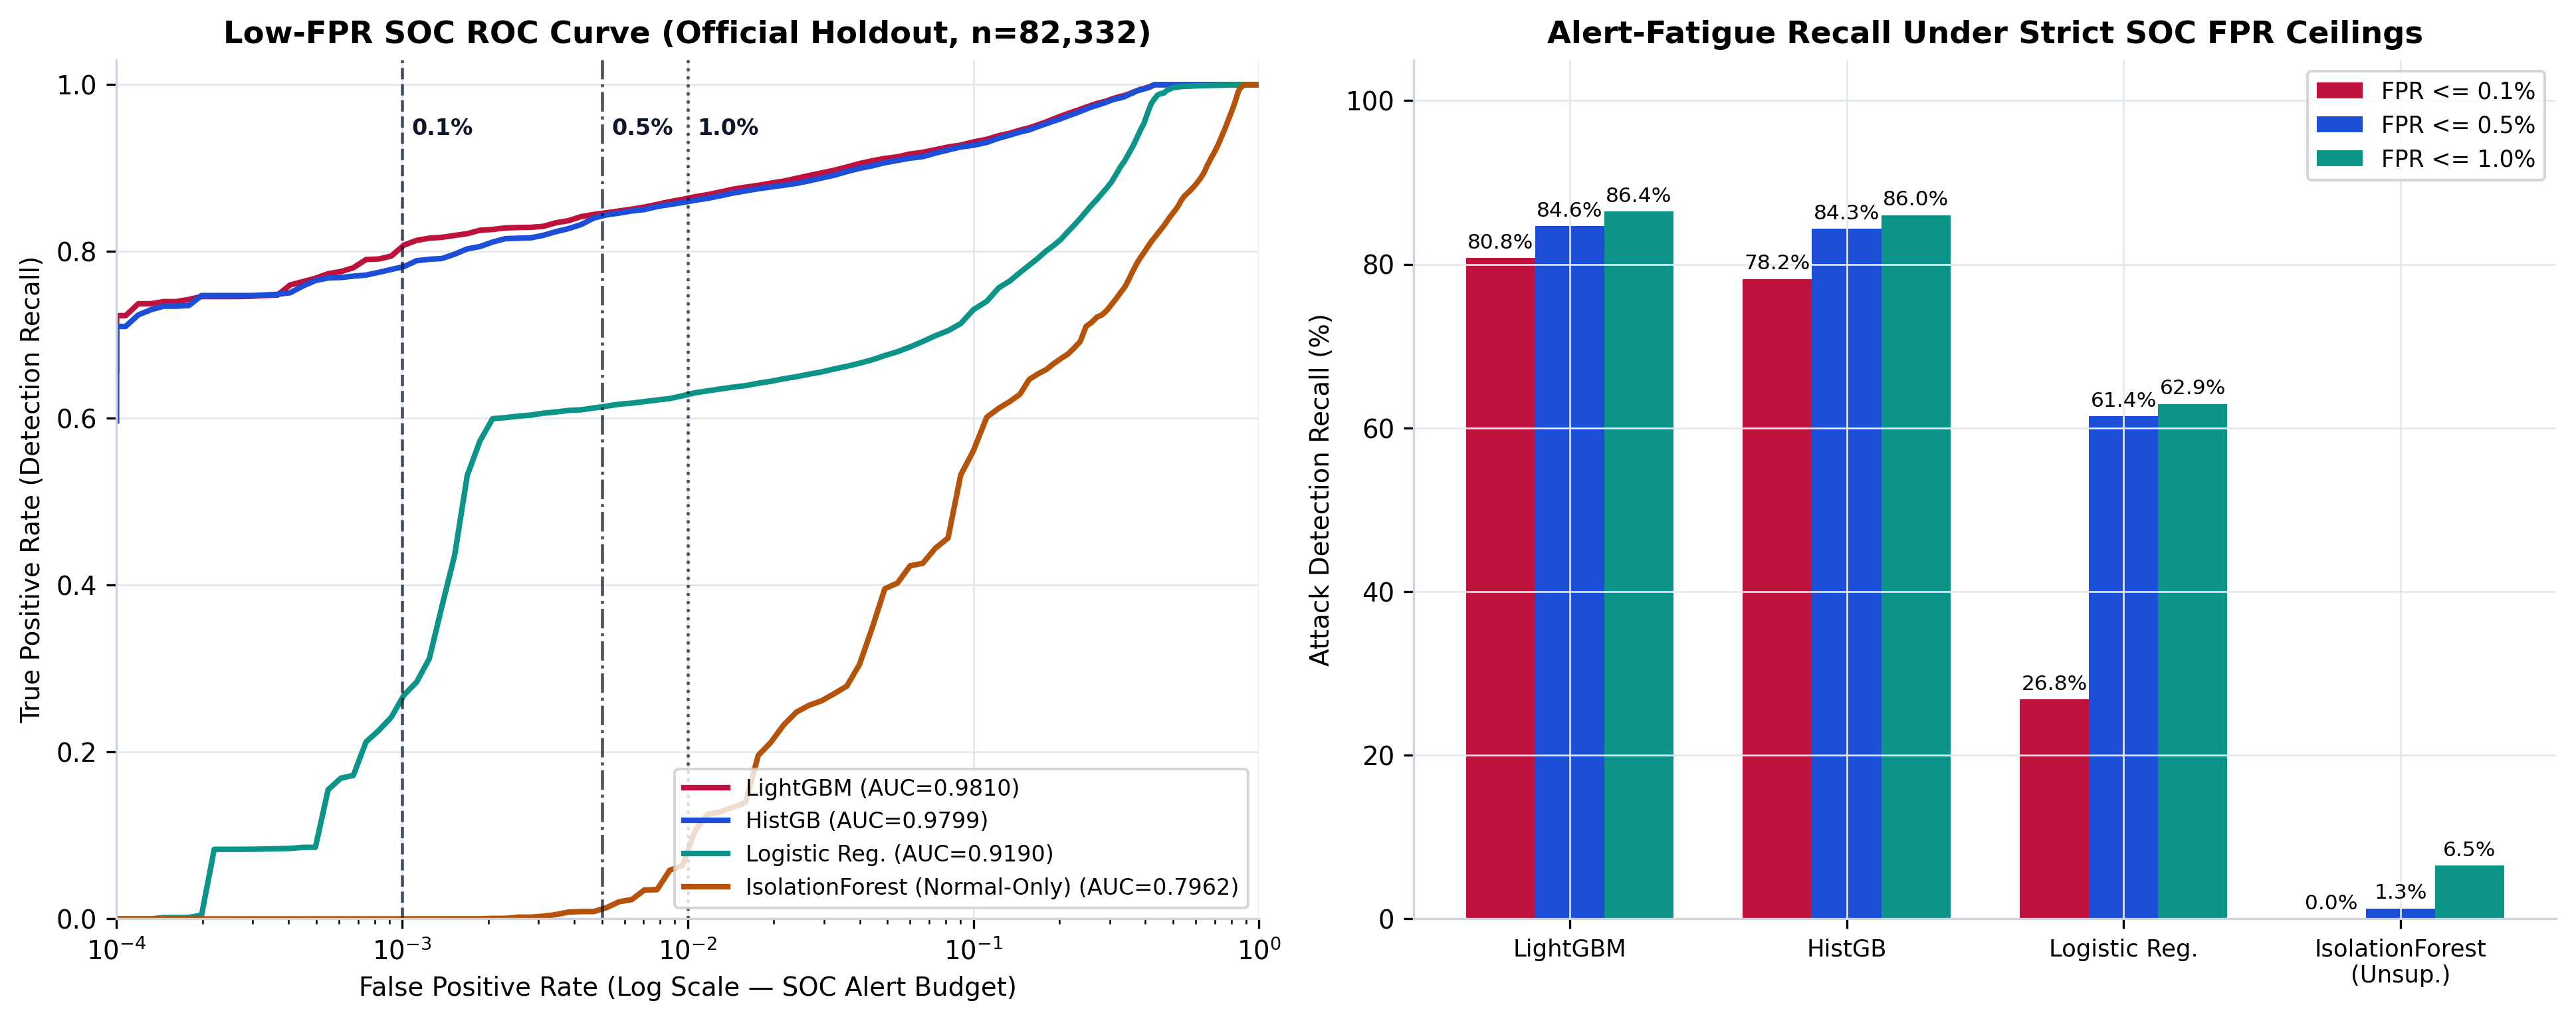

nidsz_zero_day_loao_recall.png


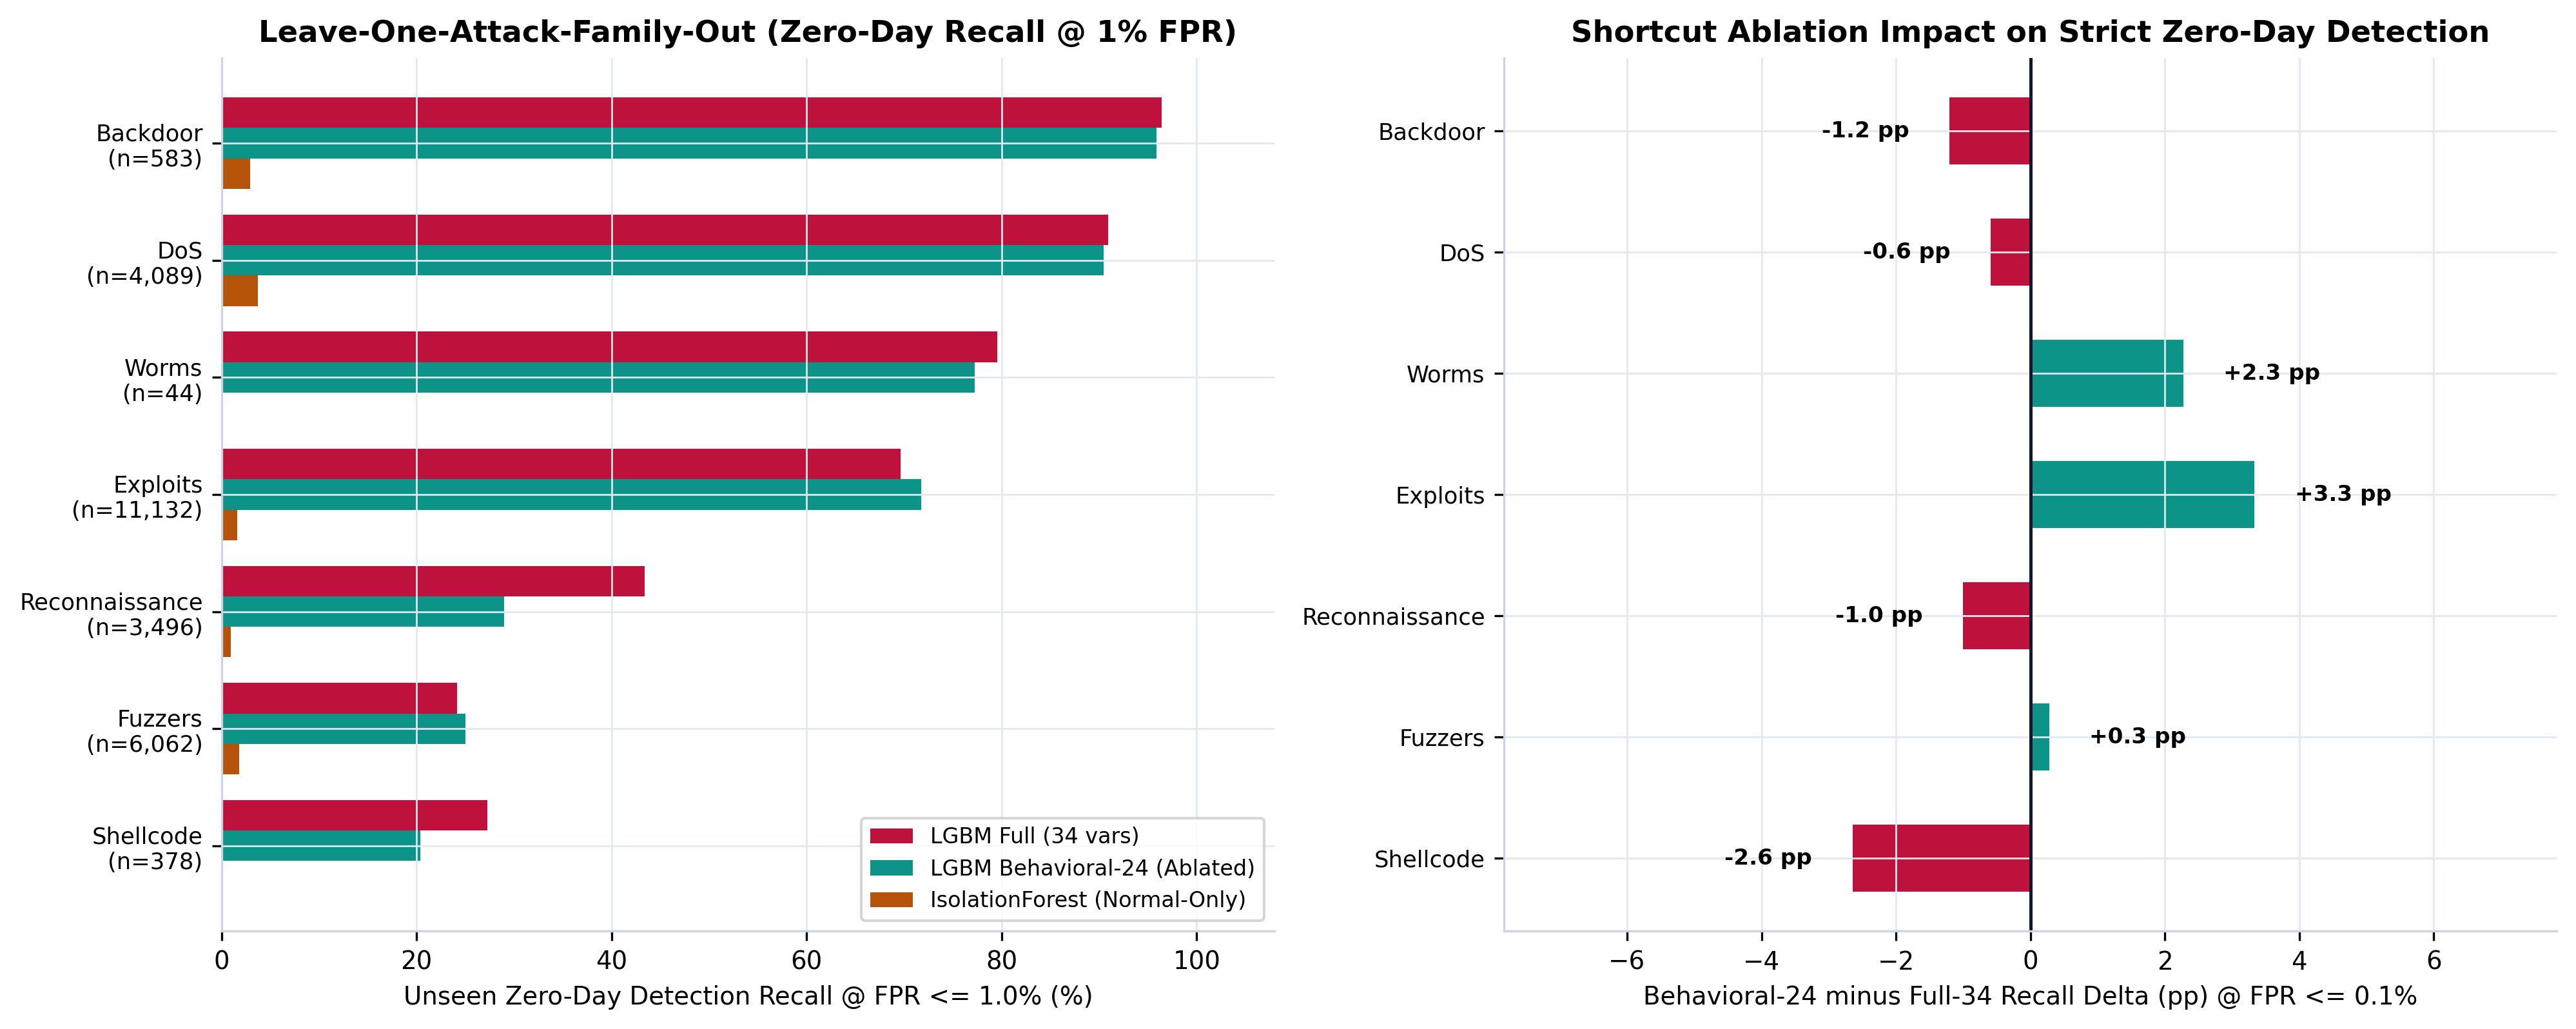

nidsz_ttl_ablation_shap.png


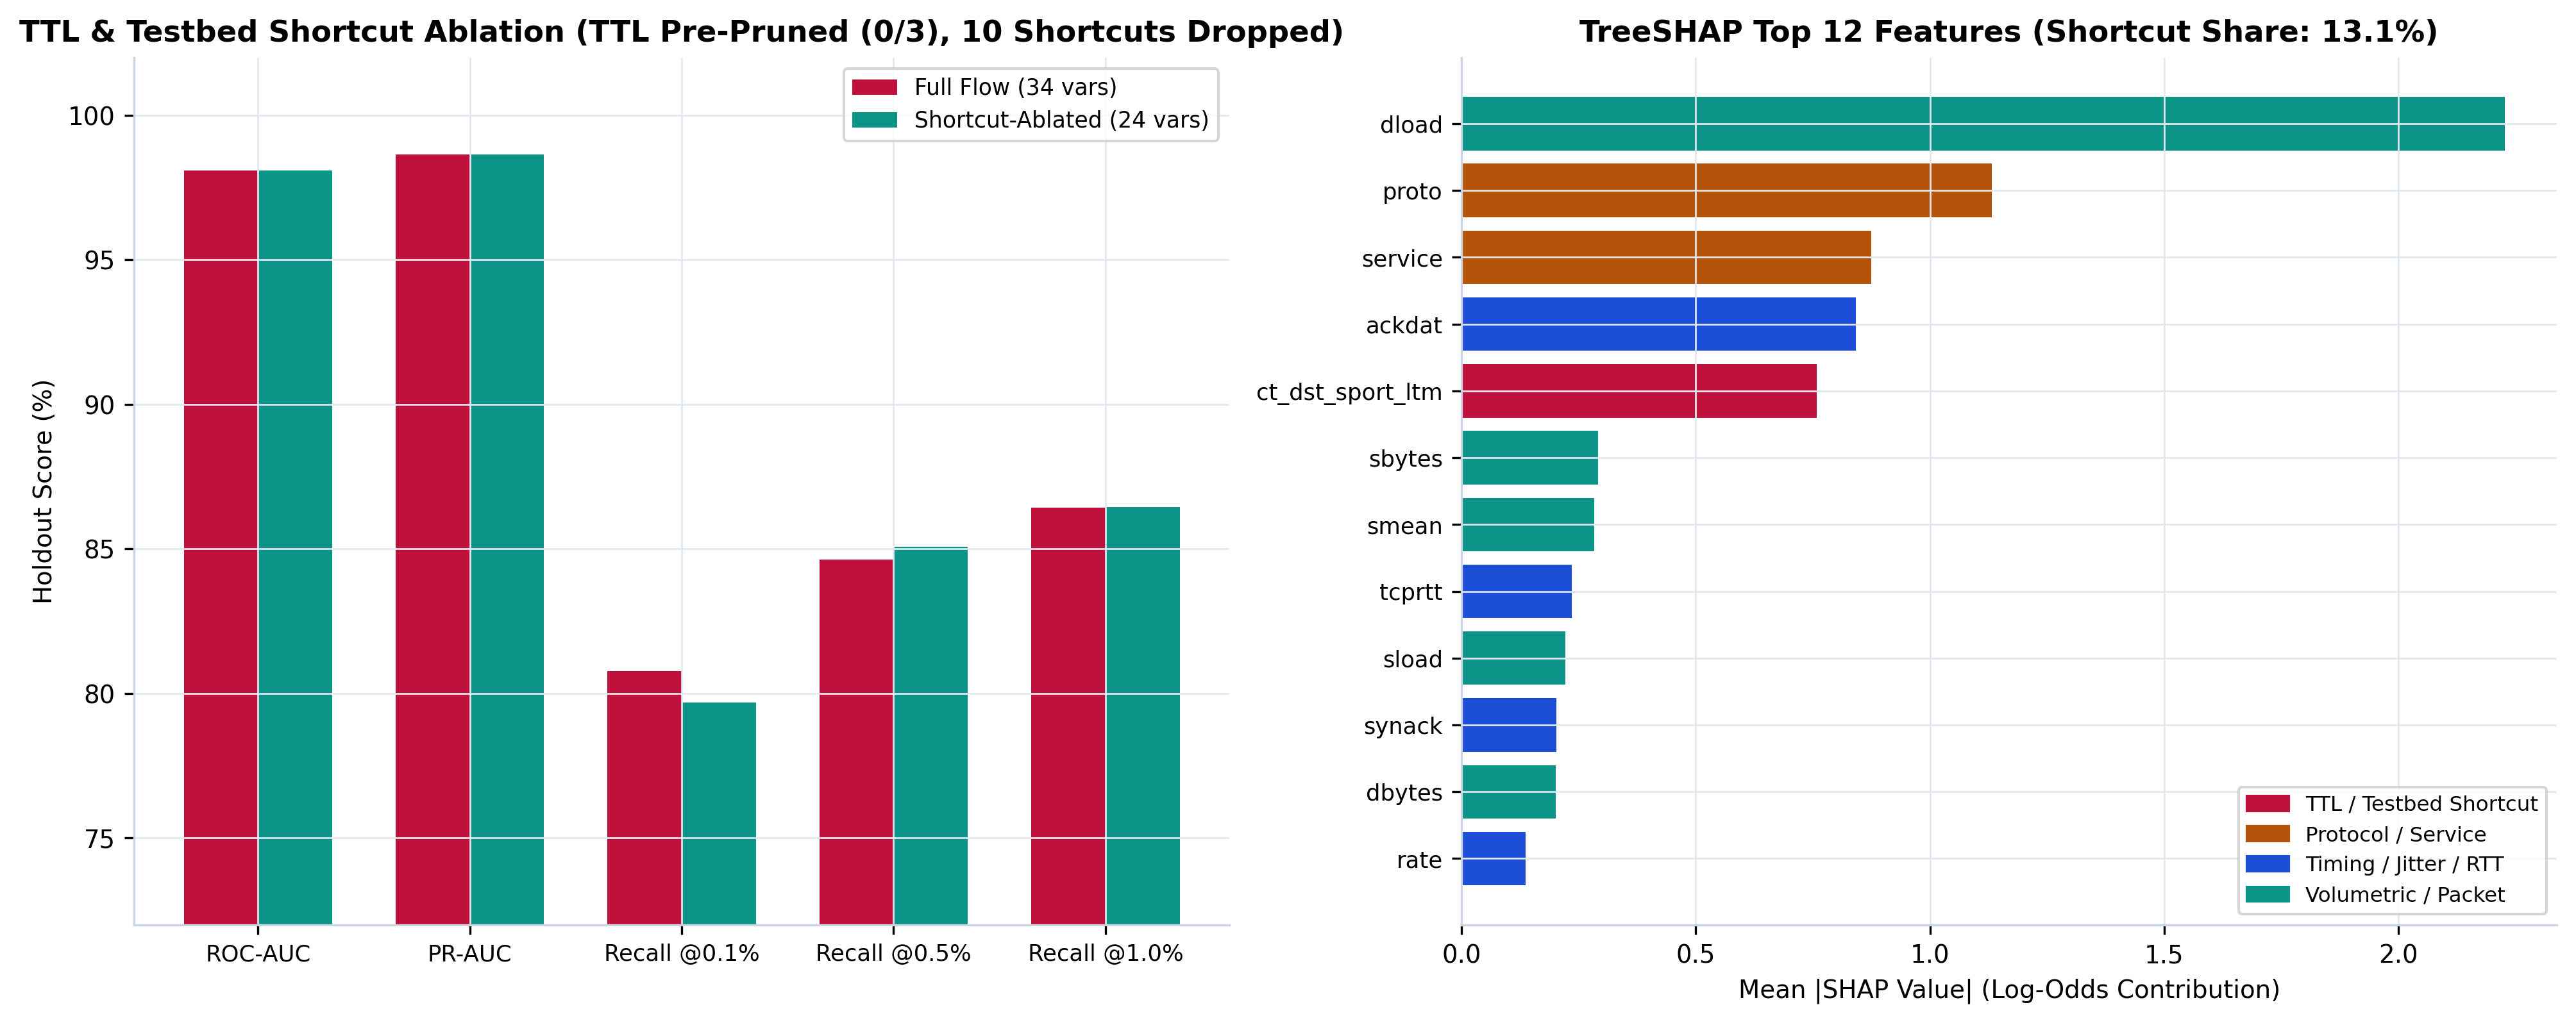

nidsz_calibration_and_latency.png


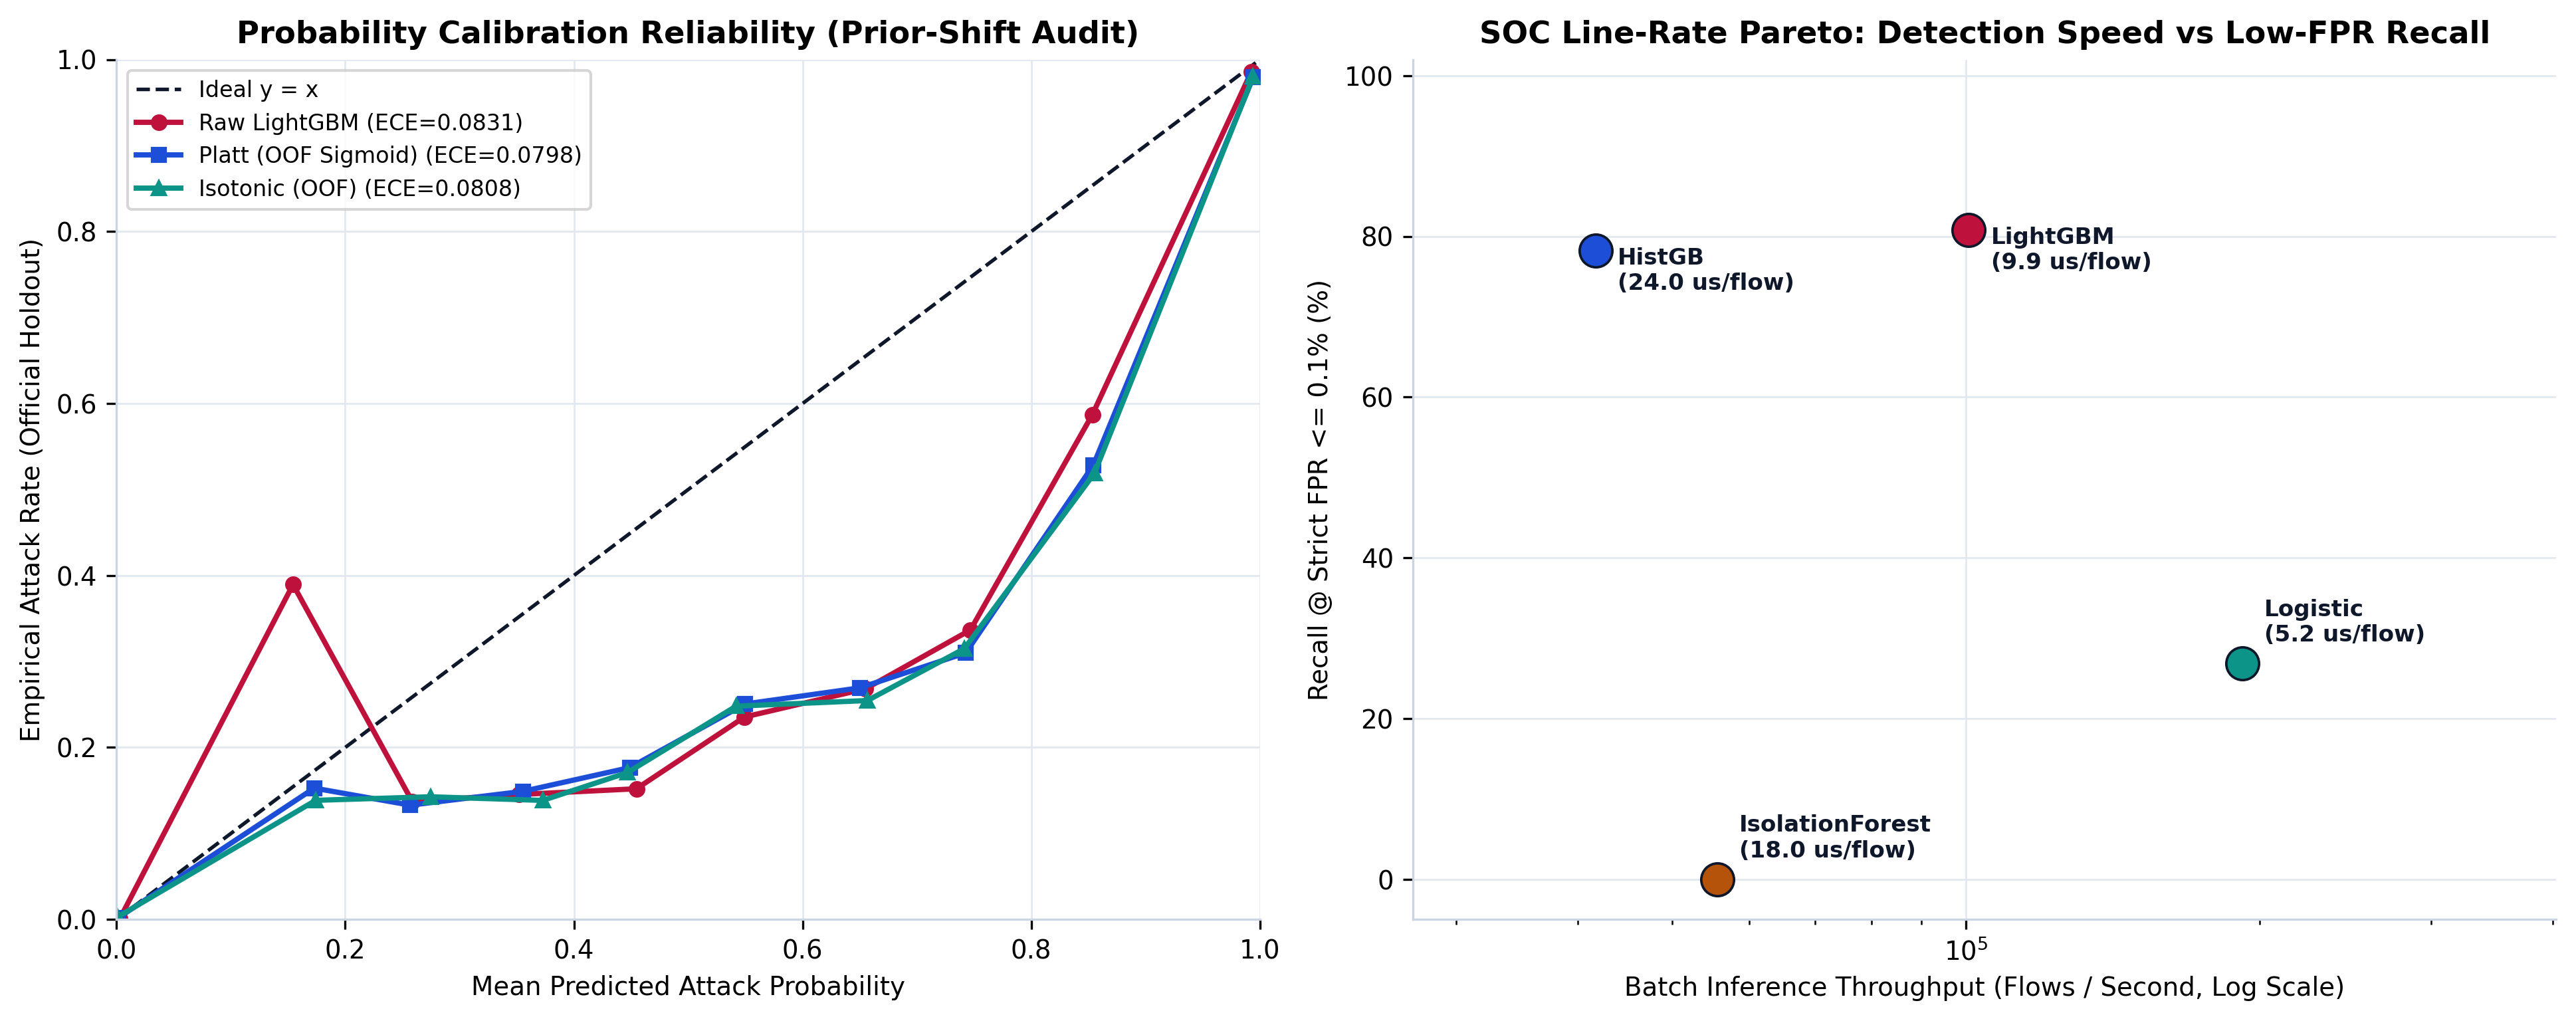

In [6]:
for img_name in [
    'nidsz_soc_roc_low_fpr.png',
    'nidsz_zero_day_loao_recall.png',
    'nidsz_ttl_ablation_shap.png',
    'nidsz_calibration_and_latency.png',
]:
    print(img_name)
    display(Image(filename=str(PROJECT_ROOT / 'images' / img_name), width=900))